In [ ]:
from pathlib import Path
import os, sys
_root = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "REPOSITORY_PROVENANCE.json").is_file()), None)
if _root is None:
    raise RuntimeError("Start Jupyter inside this experiment repository.")
os.chdir(_root)
sys.path.insert(0, str(_root))


# Neural-embedding majority IQP: development and fresh-seed validation

The encoder remains $\phi_i(s)=w_i^Ts+b_i$, with all four feature weights
independently initialized from $\mathrm{Unif}[0,2\pi)$ and trained. No
CartPole controller or feature-specific weights are inserted. The decoder is
binary majority on all measured qubits. Only the commuting circuit block,
its gate initialization, and the qubit count are varied.

The second locked model uses **21 qubits in seven disjoint entangled triples**.
For the partition $B_j=\{3j-2,3j-1,3j\}$, its circuit is
$$U(s)=H^{\otimes21}D(s)H^{\otimes21},$$
$$D(s)=\prod_{i=1}^{21}R_{Z_i}(w_i^Ts+b_i)
\prod_{j=1}^{7}\left[\prod_{\{i,k\}\subset B_j}R_{Z_iZ_k}(\beta_{ik})
R_{\prod_{i\in B_j}Z_i}(\gamma_j)\right].$$
Here $R_P(t)=e^{-itP/2}$. All gates inside $D$ commute. Initialize
$b_i=\pi/2$ and each $\beta_{ik},\gamma_j$ independently from
$\mathcal N(0,0.5^2)$. All **133 parameters** (84 feature weights,
21 biases, 21 pair angles and 7 triple angles) remain trainable.
The action probability is $\pi(0|s)=\Pr[|x|\leq10]$, and
$\pi(1|s)=1-\pi(0|s)$. This is global majority, not majority per block.
The affine encoder and binary majority are retained; the qubit count,
interaction block and gate initialization change. This initialization is
**not** the full-period uniform ensemble of the paper's variance theorem.

Each triple's four possible Hamming-weight probabilities are computed from
its exact eight-amplitude state. Convolving these seven count distributions
gives the exact global-majority policy. This model is therefore **efficiently
classically simulable**, despite its 21-qubit description. No sampling
hardness or quantum advantage is asserted.

The comparison uses the unchanged 65-parameter 4–9–2 tanh MLP, identical
REINFORCE settings, 500 episodes with 200 steps, and 100 frozen evaluation
episodes per validation seed. The user-approved freezing correction is
applied to **both** models: at least 100 completed episodes are required
before a trailing-100 mean of at least 195 can freeze learning. The check
occurs at five-episode optimizer-batch boundaries. The reported solve time
is the first full rolling-100 mean of at least 195 (checked each episode);
unsolved runs receive restricted episode 501. Neither metric measures wall-clock speed.

The first locked seven-qubit model failed fresh-seed validation under the
legacy freezing protocol; its results are retained below. Further development
used eight seeds and a corrected-protocol comparison of three finalists.
The second model was locked before examining **20 new matched seeds**.
Every scored candidate is retained. The two primary endpoints are normalized
training-return AUC (mean return divided by 200 over 500 episodes) and
restricted solve episode. We use paired-bootstrap intervals and two-sided
exact paired sign-randomization tests, Holm-adjusted across two endpoints
and multiplied by two to account conservatively for two locked comparisons.
Both endpoints must improve under this rule. This does not make the initial
search a preregistered study; it documents prospective locks within an adaptive search.
These results concern sample efficiency against this fixed baseline, not
wall-clock speed, classical hardness, or quantum advantage. The IQP model
has more trainable parameters than the baseline, so this is **not a
capacity-matched comparison**. The initialization audit separates starting
performance from trained performance.

In [1]:
from pathlib import Path
import json
from IPython.display import display, Image
ROOT = Path.cwd()
RESULTS = ROOT / "results" / "majority_iqp_model_search"
lock = json.loads((RESULTS / "locked_model_round2.json").read_text())
lock

{'model': 'iqpblocksbalanced_21_0.5',
 'parameters': 133,
 'baseline': 'mlp',
 'baseline_parameters': 65,
 'phase': 'validation_round2_strict',
 'validation_seeds': [601,
  607,
  613,
  617,
  619,
  631,
  641,
  643,
  647,
  653,
  659,
  661,
  673,
  677,
  683,
  691,
  701,
  709,
  719,
  727],
 'development_seeds': [211, 223, 227, 229, 233, 239, 241, 251],
 'selection_reason': "Fastest mean convergence among the three corrected-protocol finalists, all eight development seeds solved, and improved late and held-out returns relative to the seven-qubit finalist. The seven-qubit model's previous failed validation is retained and informed this choice; this is the second locked comparison, not the first.",
 'circuit': '21 qubits partitioned into seven disjoint triples; H D(s) H with per-qubit affine RZ encoding, all three RZZ pairs and one RZZZ in each triple, and global binary majority over all 21 bits.',
 'initialization': 'Independent affine feature weights Uniform[0,2pi); traina

## Complete development record
No trial is discarded because of its score.

In [2]:
for phase in ["development_v1", "development_v2", "development_strict"]:
    print(phase)
    display(json.loads((RESULTS / (phase + "_summary.json")).read_text()))

development_v1


{'phase': 'development_v1',
 'summary': {'iqp2body_7_0.15': {'n': 4,
   'seeds': [211, 223, 227, 229],
   'parameters': 42,
   'auc': {'mean': 0.91273, 'sem': 0.02629968028956499},
   'restricted_solve_episode': {'mean': 205.75, 'sem': 28.496710336458136},
   'final50': {'mean': 197.23999999999998, 'sem': 0.4632493928760162},
   'heldout': {'mean': 196.6, 'sem': 3.3999999999999986},
   'solved_fraction': 1.0},
  'iqp3body_7_0.15': {'n': 4,
   'seeds': [211, 223, 227, 229],
   'parameters': 42,
   'auc': {'mean': 0.9092749999999999, 'sem': 0.023704226240623554},
   'restricted_solve_episode': {'mean': 221.25, 'sem': 30.976805839208147},
   'final50': {'mean': 193.53, 'sem': 1.6054594358002314},
   'heldout': {'mean': 200.0, 'sem': 0.0},
   'solved_fraction': 1.0},
  'iqp_3_0.15': {'n': 2,
   'seeds': [211, 223],
   'parameters': 19,
   'auc': {'mean': 0.8033950000000001, 'sem': 0.07595500000000005},
   'restricted_solve_episode': {'mean': 306.0, 'sem': 47.99999999999999},
   'final50': 

development_v2


{'phase': 'development_v2',
 'summary': {'iqpblocks_15_0.15': {'n': 4,
   'seeds': [211, 223, 227, 229],
   'parameters': 95,
   'auc': {'mean': 0.8924549999999999, 'sem': 0.03746131971781024},
   'restricted_solve_episode': {'mean': 203.75, 'sem': 41.28836599656938},
   'final50': {'mean': 198.14999999999998, 'sem': 1.0859251048453276},
   'heldout': {'mean': 198.675, 'sem': 1.3250000000000028},
   'solved_fraction': 1.0},
  'iqpblocks_21_0.15': {'n': 8,
   'seeds': [211, 223, 227, 229, 233, 239, 241, 251],
   'parameters': 133,
   'auc': {'mean': 0.91250875, 'sem': 0.02063529218851425},
   'restricted_solve_episode': {'mean': 215.75, 'sem': 45.16784175241749},
   'final50': {'mean': 195.8625, 'sem': 2.386190740489953},
   'heldout': {'mean': 196.175, 'sem': 2.334026257656191},
   'solved_fraction': 0.875},
  'iqpblocks_27_0.15': {'n': 4,
   'seeds': [211, 223, 227, 229],
   'parameters': 171,
   'auc': {'mean': 0.90662, 'sem': 0.02549553980601314},
   'restricted_solve_episode': {'me

development_strict


{'phase': 'development_strict',
 'summary': {'iqp2body_7_0.15': {'n': 8,
   'seeds': [211, 223, 227, 229, 233, 239, 241, 251],
   'parameters': 42,
   'auc': {'mean': 0.94695125, 'sem': 0.017823559292358366},
   'restricted_solve_episode': {'mean': 166.0, 'sem': 20.458145426350704},
   'final50': {'mean': 197.62, 'sem': 0.9085860286338147},
   'heldout': {'mean': 197.975, 'sem': 1.6845675579040618},
   'solved_fraction': 1.0},
  'iqpblocksbalanced_21_0.15': {'n': 8,
   'seeds': [211, 223, 227, 229, 233, 239, 241, 251],
   'parameters': 133,
   'auc': {'mean': 0.91786125, 'sem': 0.02891154177817349},
   'restricted_solve_episode': {'mean': 171.375, 'sem': 21.389197457060956},
   'final50': {'mean': 200.0, 'sem': 0.0},
   'heldout': {'mean': 199.48125, 'sem': 0.5187500000000007},
   'solved_fraction': 1.0},
  'iqpblocksbalanced_21_0.5': {'n': 8,
   'seeds': [211, 223, 227, 229, 233, 239, 241, 251],
   'parameters': 133,
   'auc': {'mean': 0.92753, 'sem': 0.023432289992352747},
   'restri

## First locked validation: unsuccessful
Retained in full; this result informed subsequent development. It used the old freezing rule and must not be pooled with the corrected-protocol experiment.

In [3]:
validation = json.loads((RESULTS / "validation_summary.json").read_text())
validation

{'phase': 'validation',
 'summary': {'iqp2body_7_0.15': {'n': 20,
   'seeds': [401,
    409,
    419,
    421,
    431,
    433,
    439,
    443,
    449,
    457,
    461,
    463,
    467,
    479,
    487,
    491,
    499,
    503,
    509,
    521],
   'parameters': 42,
   'auc': {'mean': 0.851886, 'sem': 0.025802444900476104},
   'restricted_solve_episode': {'mean': 296.35, 'sem': 28.684332327119478},
   'final50': {'mean': 196.04700000000003, 'sem': 0.9954689717335291},
   'heldout': {'mean': 194.65149999999997, 'sem': 1.1269064022684778},
   'solved_fraction': 0.85},
  'mlp': {'n': 20,
   'seeds': [401,
    409,
    419,
    421,
    431,
    433,
    439,
    443,
    449,
    457,
    461,
    463,
    467,
    479,
    487,
    491,
    499,
    503,
    509,
    521],
   'parameters': 65,
   'auc': {'mean': 0.8245520000000001, 'sem': 0.00828871885853233},
   'restricted_solve_episode': {'mean': 277.05, 'sem': 19.034107198450503},
   'final50': {'mean': 199.27100000000002, 

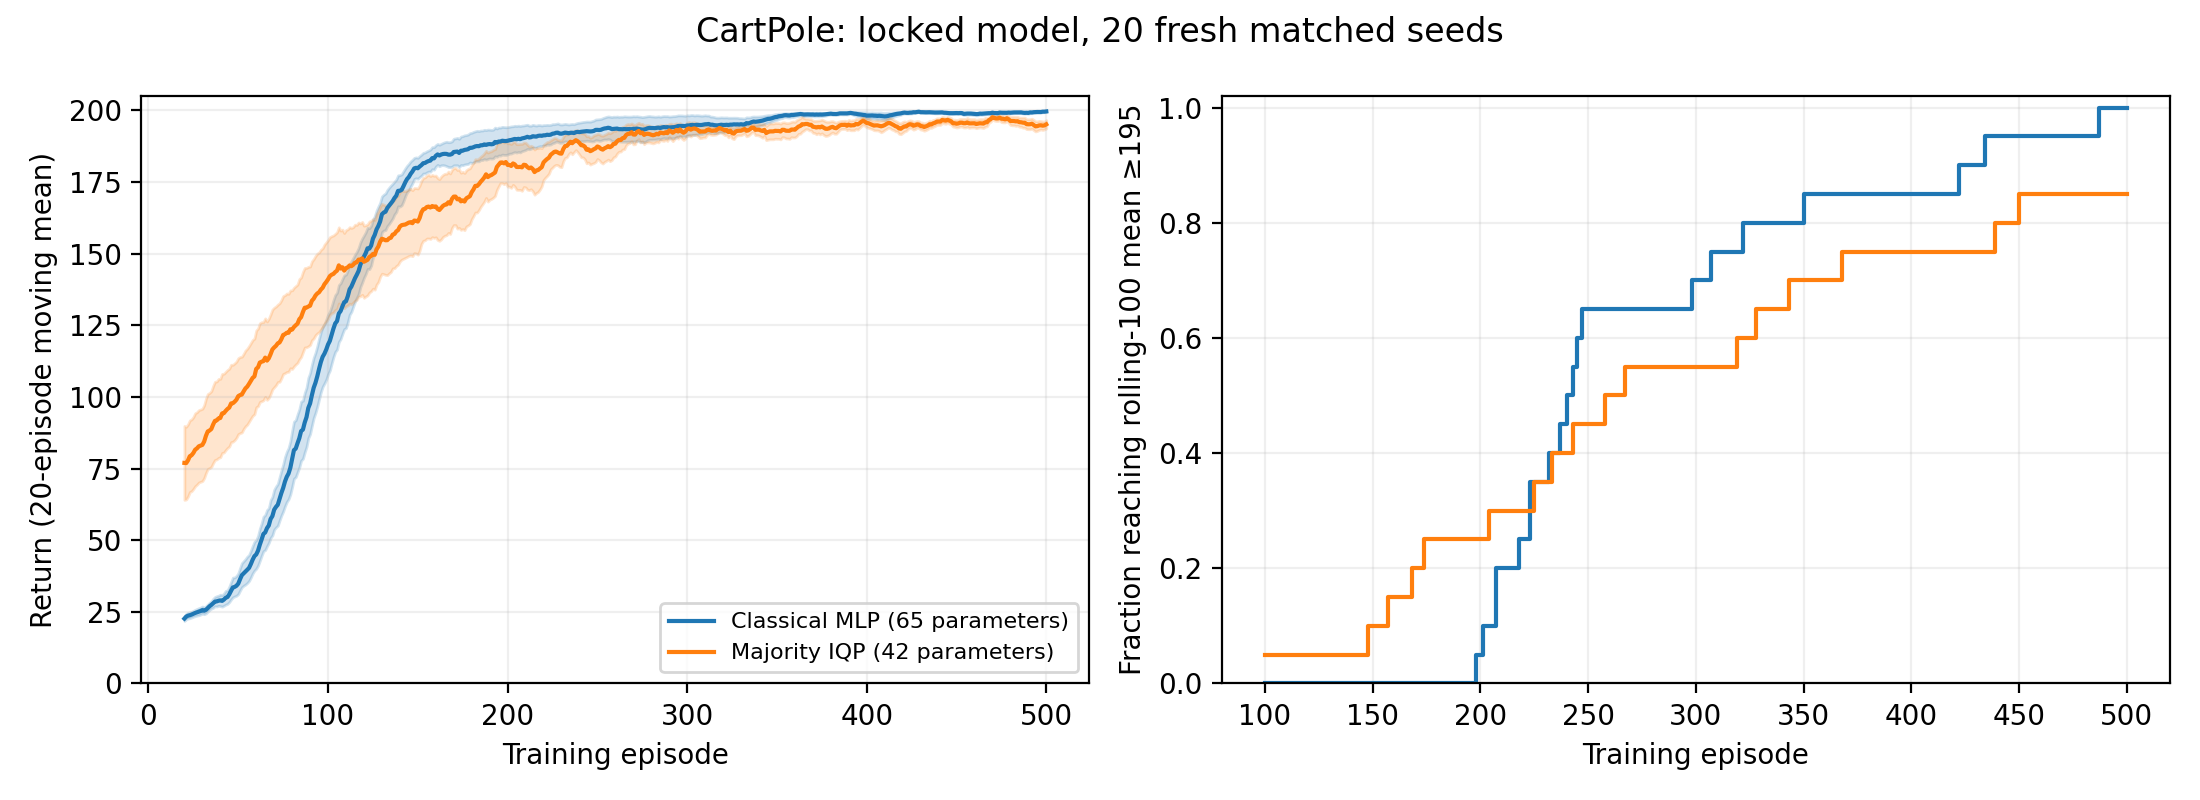

In [4]:
display(Image(filename=str(RESULTS / "validation_comparison.png")))

## Second locked validation: corrected protocol
Interpret both primary endpoints and report terminal performance separately. Positive differences mean higher IQP AUC or fewer IQP episodes to solve.

In [5]:
validation_round2 = json.loads((RESULTS / "validation_round2_strict_summary.json").read_text())
validation_round2

{'phase': 'validation_round2_strict',
 'summary': {'iqpblocksbalanced_21_0.5': {'n': 20,
   'seeds': [601,
    607,
    613,
    617,
    619,
    631,
    641,
    643,
    647,
    653,
    659,
    661,
    673,
    677,
    683,
    691,
    701,
    709,
    719,
    727],
   'parameters': 133,
   'auc': {'mean': 0.9256485, 'sem': 0.011076774237708281},
   'restricted_solve_episode': {'mean': 174.6, 'sem': 10.94805918873295},
   'final50': {'mean': 197.651, 'sem': 1.1041219183252884},
   'heldout': {'mean': 198.12900000000002, 'sem': 0.6748044161088457},
   'solved_fraction': 1.0},
  'mlp': {'n': 20,
   'seeds': [601,
    607,
    613,
    617,
    619,
    631,
    641,
    643,
    647,
    653,
    659,
    661,
    673,
    677,
    683,
    691,
    701,
    709,
    719,
    727],
   'parameters': 65,
   'auc': {'mean': 0.8250794999999999, 'sem': 0.00923099742215838},
   'restricted_solve_episode': {'mean': 290.25, 'sem': 15.955509690188032},
   'final50': {'mean': 198.06700

In [6]:
from IPython.display import Markdown
q = validation_round2["summary"][lock["model"]]
c = validation_round2["summary"]["mlp"]
rows = ["| Metric | Majority IQP | Classical MLP |", "|---|---:|---:|"]
for key, label in [("auc", "Normalized training AUC"),
                   ("restricted_solve_episode", "Episodes to rolling-100 mean ≥195"),
                   ("heldout", "Frozen held-out return")]:
    rows.append(f"| {label} | {q[key]['mean']:.3f} | {c[key]['mean']:.3f} |")
display(Markdown("\n".join(rows)))
print("Both locked primary endpoints passed:", validation_round2["passes_locked_success_rule"])

| Metric | Majority IQP | Classical MLP |
|---|---:|---:|
| Normalized training AUC | 0.926 | 0.825 |
| Episodes to rolling-100 mean ≥195 | 174.600 | 290.250 |
| Frozen held-out return | 198.129 | 198.248 |

Both locked primary endpoints passed: True


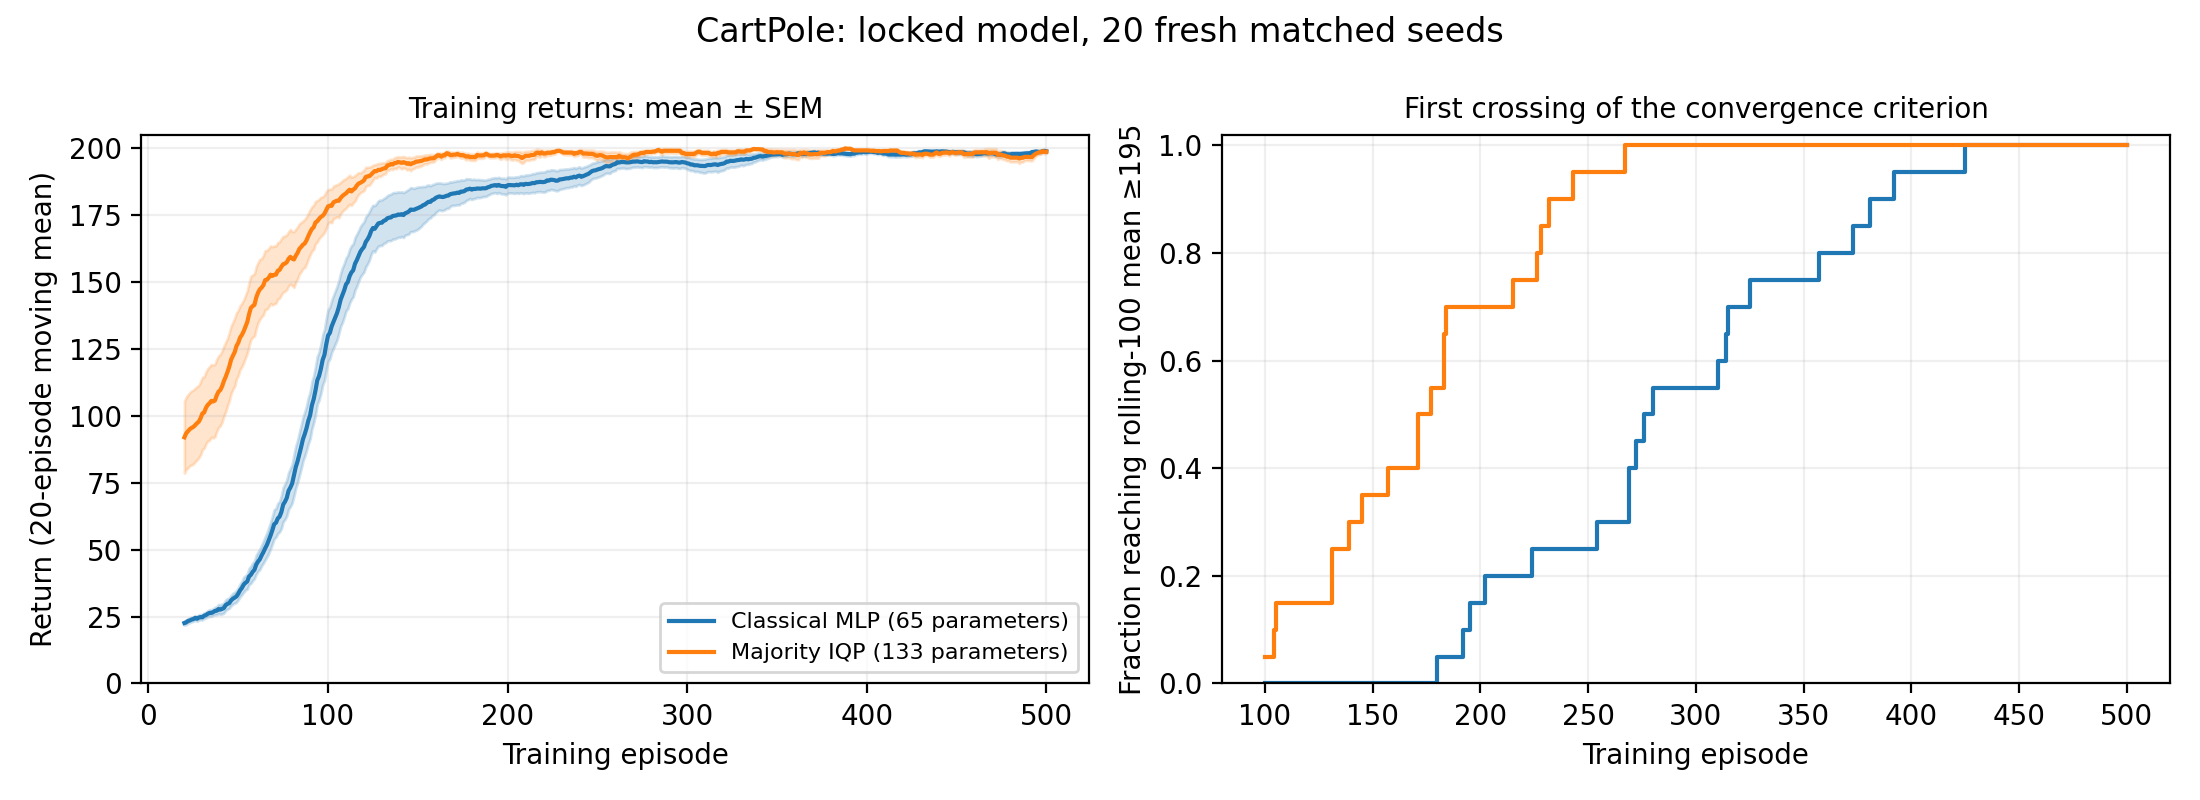

In [7]:
display(Image(filename=str(RESULTS / "validation_round2_strict_comparison.png")))

## Starting-policy audit
These evaluations were not used to select the model. An advantage at initialization contributes to training AUC and should not be attributed entirely to faster parameter optimization.

In [8]:
import numpy as np
audit = json.loads((RESULTS / "validation_round2_strict_initial_policy_audit.json").read_text())
for name in sorted({r["model"] for r in audit}):
    group = [r for r in audit if r["model"] == name]
    print(name, "initial mean:", np.mean([r["initial_mean_return"] for r in group]),
          "trained mean:", np.mean([r["trained_mean_return"] for r in group]))

iqpblocksbalanced_21_0.5 initial mean: 82.83349999999999 trained mean: 198.12900000000002
mlp initial mean: 19.293000000000003 trained mean: 198.24800000000002


## Numerical verification
Circuit probabilities were checked against PennyLane and gradients against finite differences. The following check compares a complete optimizer batch against the unmodified QASP trainer.

In [9]:
json.loads((RESULTS / "training_equivalence_check.json").read_text())

[{'model': 'iqp2body_7_0.15',
  'native_and_batched_returns': [[31.0, 28.0, 59.0, 35.0, 39.0],
   [31.0, 28.0, 59.0, 35.0, 39.0]],
  'max_parameter_difference_after_update': 0.0},
 {'model': 'mlp',
  'native_and_batched_returns': [[30.0, 16.0, 24.0, 18.0, 26.0],
   [30.0, 16.0, 24.0, 18.0, 26.0]],
  'max_parameter_difference_after_update': 2.9802322387695312e-08},
 {'model': 'iqpblocksbalanced_21_0.15',
  'native_and_batched_returns': [[31.0, 28.0, 40.0, 40.0, 36.0],
   [31.0, 28.0, 40.0, 40.0, 36.0]],
  'max_parameter_difference_after_update': 1.7695128917694092e-07}]

In [10]:
json.loads((RESULTS / "strict_window_regression_checks.json").read_text())

[{'early_good_episodes_only': False,
  'freeze_episode': 100,
  'optimizer_updates': 19},
 {'early_good_episodes_only': True,
  'freeze_episode': None,
  'optimizer_updates': 22},
 {'model': 'mlp',
  'unchanged_pre_freeze_trajectory': True,
  'parameter_difference': 0.0},
 {'model': 'iqpblocksbalanced_21_0.15',
  'unchanged_pre_freeze_trajectory': True,
  'parameter_difference': 0.0}]

In [11]:
json.loads((RESULTS / "block_circuit_checks.json").read_text())

[{'family': 'iqpblocks',
  'qubits': 9,
  'sigma': 0.15,
  'max_weight_distribution_error': 4.078402271456838e-08,
  'interaction_gradient_error': 3.0627474188804626e-05},
 {'family': 'iqpblocks',
  'qubits': 15,
  'sigma': 0.15,
  'max_weight_distribution_error': 1.3637477569439227e-07,
  'interaction_gradient_error': 5.338340997695923e-06},
 {'family': 'iqpblocksbalanced',
  'qubits': 9,
  'sigma': 0.15,
  'max_weight_distribution_error': 1.1329370314117071e-07,
  'interaction_gradient_error': 5.034729838371277e-06},
 {'family': 'iqpblocksbalanced',
  'qubits': 15,
  'sigma': 0.15,
  'max_weight_distribution_error': 1.0956438711851035e-07,
  'interaction_gradient_error': 1.385621726512909e-05},
 {'family': 'iqpblocksbalanced',
  'qubits': 21,
  'sigma': 0.5,
  'max_weight_distribution_error': 8.72871808166309e-08,
  'interaction_gradient_error': 1.5133991837501526e-05}]

In [12]:
integrity = json.loads((RESULTS / "validation_round2_strict_integrity.json").read_text())
print("Audited runs:", integrity["runs_checked"])
integrity["versions"]

Audited runs: 40


{'numpy': '2.2.6',
 'torch': '2.7.0',
 'pennylane': '0.42.2',
 'gymnasium': '1.0.0',
 'qasp': '0.1.0',
 'joblib': '1.5.0',
 'nbformat': '5.10.4',
 'nbclient': '0.10.4'}

## Reproduction

Use the `torchlane` environment and the scripts beside this notebook:

```bash
python majority_iqp_model_search.py preflight
python test_majority_iqp_training_equivalence.py
python majority_iqp_block_model.py
python test_strict_window_trainer.py
python majority_iqp_model_search.py run --phase validation_round2_strict --models iqpblocksbalanced_21_0.5 mlp --seeds 601 607 613 617 619 631 641 643 647 653 659 661 673 677 683 691 701 709 719 727 --jobs 3
python analyze_majority_iqp_search.py validation_round2_strict
python audit_majority_initial_policy.py validation_round2_strict --jobs 3 --episodes 100
python verify_majority_iqp_results.py
```

Completed runs are reused. Per-seed checkpoints contain both initial and
final tensors; raw training and evaluation returns are saved separately.
Historical development and the first locked validation remain in their
original directories; the corrected protocol uses the `strict` suffix.
The interrupted initial pilot directory `development` is excluded because
of a checkpoint-naming bug; scored runs use the corrected `development_v1`.
Do not treat development-seed performance as confirmatory evidence.